<a href="https://colab.research.google.com/github/Gene7Ai/genai-tps/blob/main/TP3/TP3_2_DDPM_Training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP3.2 — Implementing DDPM and Training Process

**Introduction to Deep Generative Models  **

For each practical exercise (TP), please work in groups of two or three. Then, create a private GitHub repository and add me (my GitHub is **arthur-75**) to your project.

In this exercise we will be training a Denoising Diffusion Probabilistic Model (DDPM).

> **Student note:** Complete all `xxx` placeholders and required definitions yourselves. This notebook preserves the unfinished code in the source. It refers to code from TP3.1 and external files such as `diffusion_utilities.py`, dataset `.npy` files, and model weights; they are not bundled here.

## 1. Set up

- Use the same network hyperparameters & diffusion hyperparameters of the previous exercise.
- Build your:
  - DDPM noise schedule
  - Context U-net
  - Function that removes the predicted noise
  - Sampling function

### Training hyperparameters

In [ ]:
# get the course files from the Drive "cours 4 DM" (gdown is already installed on Colab)
# or upload them by hand: diffusion_utilities.py, the models/ folder and the data/ folder
import os
import gdown

if not os.path.exists("diffusion_utilities.py"):
    gdown.download(id="1xN0YQfdAdYjF2mpAftCpBBYfxMdwgjpN", output="diffusion_utilities.py")
if not os.path.exists("models"):
    gdown.download_folder(id="1u9Xl23P1C8TNKa6SZxnx4XS6BaurwVoX", output="models")
print(os.listdir("models"))
if not os.path.exists("data"):
    gdown.download_folder(id="1cCSrrZeoJ6f5lMTqaqV75Avl2uoYsGCR", output="data")
print(os.listdir("data"))

Downloading...
From (original): https://drive.google.com/uc?id=1xN0YQfdAdYjF2mpAftCpBBYfxMdwgjpN
From (redirected): https://drive.google.com/uc?id=1xN0YQfdAdYjF2mpAftCpBBYfxMdwgjpN&confirm=t&uuid=1f5a0519-e3f3-4dee-8d6e-1078ad2f582b
To: /content/diffusion_utilities.py
100%|██████████| 9.93k/9.93k [00:00<00:00, 26.9MB/s]
Retrieving folder contents


Processing file 1RncKsQi1mmrktyo6c9jLWELW586VJf9U context_model_0.pth
Processing file 1OtOHPYEIeu3-CEhnY15ZZDifMd44C8zv context_model_4.pth
Processing file 1ySVxtx4sK4EMAIZ0cddXHzR9hA6RK4oB context_model_8.pth
Processing file 1bRl2n232PxmZkWdiniTCtWT668fGd005 context_model_12.pth
Processing file 1wbdzTWVTQeUo2mK9H3Ip_nSFRpfnSMhO context_model_16.pth
Processing file 1obwI64lar7q_TiO9LqPVIEEc4NkSBuuz context_model_20.pth
Processing file 1s47l76eoYovZsl3P_qLK2D5qTXEaDJFa context_model_24.pth
Processing file 1HtvZ6VkfaCkSizjVqs69j53WVaKhe6s6 context_model_28.pth
Processing file 1qYpKkZk6mt1r-uXNglfOixPZLoey5if_ context_model_31.pth
Processing file 1QfhraKeTtOTAIBjCExA4zWUPMf55H9z8 context_model_trained.pth
Processing file 1miK3sxBOdOUlvi25NEW-tYnnJruhB1P4 model_0.pth
Processing file 1rF907kKhk25QVt_hVuhTcFG26GeA8Fg2 model_4.pth
Processing file 1XHXFOr29JvEL4cBYoIUWqr2gtVA5cqYP model_8.pth
Processing file 1pnf1bm7t4ouaPIP6zqAxFhdb-38aRKwJ model_12.pth
Processing file 1Tsv8Gq2Zhr9ruC3yhnNnkS

Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1RncKsQi1mmrktyo6c9jLWELW586VJf9U
To: /content/models/context_model_0.pth
100%|██████████| 5.99M/5.99M [00:00<00:00, 39.2MB/s]
Downloading...
From: https://drive.google.com/uc?id=1OtOHPYEIeu3-CEhnY15ZZDifMd44C8zv
To: /content/models/context_model_4.pth
100%|██████████| 5.99M/5.99M [00:00<00:00, 35.5MB/s]
Downloading...
From: https://drive.google.com/uc?id=1ySVxtx4sK4EMAIZ0cddXHzR9hA6RK4oB
To: /content/models/context_model_8.pth
100%|██████████| 5.99M/5.99M [00:00<00:00, 39.6MB/s]
Downloading...
From: https://drive.google.com/uc?id=1bRl2n232PxmZkWdiniTCtWT668fGd005
To: /content/models/context_model_12.pth
100%|██████████| 5.99M/5.99M [00:00<00:00, 39.9MB/s]
Downloading...
From: https://drive.google.com/uc?id=1wbdzTWVTQeUo2mK9H3Ip_nSFRpfnSMhO
To: /content/models/context_model_16.pth
100%|██████████| 5.99M/5.99M [00:00<00:00, 39.6MB/s

['model_16.pth', 'context_model_8.pth', 'model_12.pth', 'model_trained.pth', 'context_model_31.pth', 'context_model_0.pth', 'context_model_trained.pth', 'context_model_24.pth', 'model_4.pth', 'context_model_16.pth', 'model_28.pth', 'context_model_4.pth', 'model_0.pth', 'model_24.pth', 'context_model_12.pth', 'context_model_20.pth', 'model_31.pth', 'context_model_28.pth', 'model_20.pth', 'model_8.pth']
Processing file 1qyCRbJNrQQXShIpLon-wV2sX_LKLVm85 sprite_labels_nc_1788_16x16.npy
Processing file 18tNPeb99H4W6uzlntgPn4oLD80jnLLDP sprites_1788_16x16.npy


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1qyCRbJNrQQXShIpLon-wV2sX_LKLVm85
To: /content/data/sprite_labels_nc_1788_16x16.npy
100%|██████████| 3.58M/3.58M [00:00<00:00, 9.08MB/s]
Downloading...
From: https://drive.google.com/uc?id=18tNPeb99H4W6uzlntgPn4oLD80jnLLDP
To: /content/data/sprites_1788_16x16.npy
100%|██████████| 68.7M/68.7M [00:01<00:00, 53.5MB/s]

['sprites_1788_16x16.npy', 'sprite_labels_nc_1788_16x16.npy']



Download completed


In [ ]:
from tqdm import tqdm
import torch
import os
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML
from diffusion_utilities import ResidualConvBlock, UnetUp, UnetDown, EmbedFC, plot_sample, CustomDataset, transform

# training hyperparameters
batch_size = 100
n_epoch = 2
lrate = 1e-3

### Reuse your implementation from TP3.1

Set up the same noise schedule, Context U-Net, DDPM denoising helper and sampler before training.

In [ ]:
# from TP3.1
# diffusion hyperparameters
timesteps = 500
beta1 = 1e-4
beta2 = 0.02

# network hyperparameters
device = torch.device("cuda:0" if torch.cuda.is_available() else torch.device('cpu'))
n_feat = 64  # 64 hidden dimension feature
n_cfeat = 5  # context vector is of size 5
height = 16  # 16x16 image
save_dir = './weights/'  # our checkpoints (the teacher's ones are in ./models/)

# construct DDPM noise schedule
b_t = beta1 + ((beta2 - beta1) * torch.linspace(0, 1, timesteps + 1, device=device))
a_t = 1 - b_t
ab_t = torch.cumsum(a_t.log(), dim=0).exp()
ab_t[0] = 1


class ContextUnet(nn.Module):
    def __init__(self, in_channels, n_feat=256, n_cfeat=10, height=28):  # cfeat - context features
        super(ContextUnet, self).__init__()

        # number of input channels, number of intermediate feature maps and number of classes
        self.in_channels = in_channels
        self.n_feat = n_feat
        self.n_cfeat = n_cfeat
        self.h = height  # assume h == w. must be divisible by 4, so 28,24,20,16...

        # Initialize the initial convolutional layer
        self.init_conv = ResidualConvBlock(in_channels, n_feat, is_res=True)

        # Initialize the down-sampling path of the U-Net with two levels
        self.down1 = UnetDown(n_feat, n_feat)        # down1 #[10, 256, 8, 8]
        self.down2 = UnetDown(n_feat, 2 * n_feat)    # down2 #[10, 256, 4, 4]

        # original: self.to_vec = nn.Sequential(nn.AvgPool2d(7), nn.GELU())
        self.to_vec = nn.Sequential(nn.AvgPool2d((4)), nn.GELU())

        # Embed the timestep and context labels with a one-layer fully connected neural network
        self.timeembed1 = EmbedFC(1, 2*n_feat)
        self.timeembed2 = EmbedFC(1, 1*n_feat)
        self.contextembed1 = EmbedFC(n_cfeat, 2*n_feat)
        self.contextembed2 = EmbedFC(n_cfeat, 1*n_feat)

        # Initialize the up-sampling path of the U-Net with three levels
        self.up0 = nn.Sequential(
            nn.ConvTranspose2d(2 * n_feat, 2 * n_feat, self.h//4, self.h//4),  # up-sample
            nn.GroupNorm(8, 2 * n_feat),  # normalize
            nn.ReLU(),
        )
        self.up1 = UnetUp(4 * n_feat, n_feat)
        self.up2 = UnetUp(2 * n_feat, n_feat)

        # Initialize the final convolutional layers to map to same number of channels as input
        self.out = nn.Sequential(
            nn.Conv2d(2 * n_feat, n_feat, 3, 1, 1),  # reduce number of feature maps
            nn.GroupNorm(8, n_feat),  # normalize
            nn.ReLU(),
            nn.Conv2d(n_feat, self.in_channels, 3, 1, 1),  # map to same number of channels as input
        )

    def forward(self, x, t, c=None):
        """
        x : (batch, n_feat, h, w) : input image
        t : (batch, n_cfeat) : time step
        c : (batch, n_classes) : context label
        """
        # x is the input image, c is the context label, t is the timestep,
        # context_mask says which samples to block the context on
        x = self.init_conv(x)
        down1 = self.down1(x)          #[10, 256, 8, 8]
        down2 = self.down2(down1)      #[10, 256, 4, 4]
        hiddenvec = self.to_vec(down2)

        # mask out context if context_mask == 1
        if c is None:
            c = torch.zeros(x.shape[0], self.n_cfeat).to(x)

        # embed context and timestep
        cemb1 = self.contextembed1(c).view(-1, self.n_feat * 2, 1, 1)
        temb1 = self.timeembed1(t).view(-1, self.n_feat * 2, 1, 1)
        cemb2 = self.contextembed2(c).view(-1, self.n_feat, 1, 1)
        temb2 = self.timeembed2(t).view(-1, self.n_feat, 1, 1)

        up1 = self.up0(hiddenvec)
        up2 = self.up1(cemb1*up1 + temb1, down2)
        up3 = self.up2(cemb2*up2 + temb2, down1)
        out = self.out(torch.cat((up3, x), 1))
        return out


nn_model = ContextUnet(in_channels=3, n_feat=n_feat, n_cfeat=n_cfeat, height=height).to(device)


# helper function; removes the predicted noise (but adds some noise back in to avoid collapse)
def denoise_add_noise(x, t, pred_noise, z=None):
    if z is None:
        z = torch.randn_like(x)
    noise = b_t.sqrt()[t] * z
    mean = (x - pred_noise * ((1 - a_t[t]) / (1 - ab_t[t]).sqrt())) / a_t[t].sqrt()
    return mean + noise


# sample using standard algorithm
@torch.no_grad()
def sample_ddpm(n_sample, save_rate=20):
    # x_T ~ N(0, 1), sample initial noise
    samples = torch.randn(n_sample, 3, height, height).to(device)

    # array to keep track of generated steps for plotting
    intermediate = []
    for i in range(timesteps, 0, -1):
        print(f'sampling timestep {i:3d}', end='\r')

        # reshape time tensor
        t = torch.tensor([i / timesteps])[:, None, None, None].to(device)

        # sample some random noise to inject back in. For i = 1, don't add back in noise
        z = torch.randn_like(samples) if i > 1 else 0

        eps = nn_model(samples, t)    # predict noise e_(x_t,t)
        samples = denoise_add_noise(samples, i, eps, z)
        if i % save_rate == 0 or i == timesteps or i < 8:
            intermediate.append(samples.detach().cpu().numpy())

    intermediate = np.stack(intermediate)
    return samples, intermediate

## 2. Preparing the Dataset and Optimizer

- Load the dataset using a custom PyTorch Dataset.
- Wrap it in a DataLoader for batch processing.
- Define an Adam optimizer to update model parameters.
- Plot a few samples.

sprite shape: (89400, 16, 16, 3)
labels shape: (89400, 5)


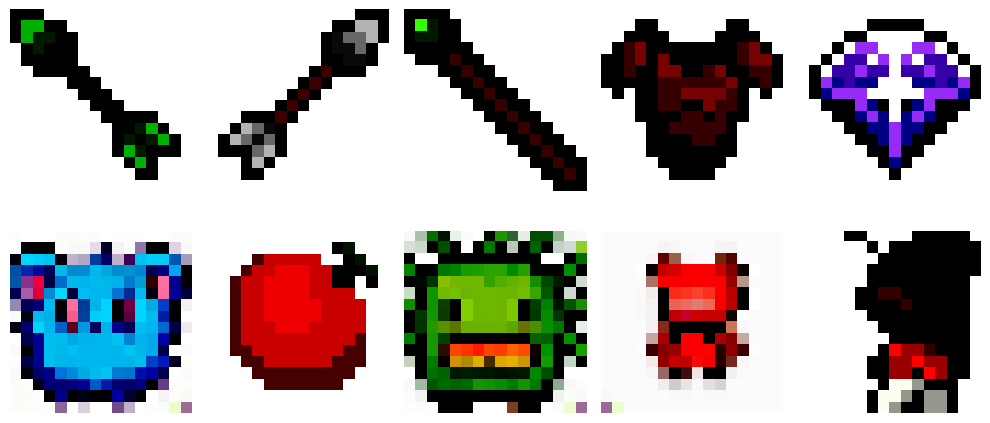

In [ ]:
# load dataset and construct optimizer
dataset = CustomDataset("./data/sprites_1788_16x16.npy",
                        "./data/sprite_labels_nc_1788_16x16.npy", transform, null_context=False)
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=1)
optim = torch.optim.Adam(nn_model.parameters(), lr=lrate)

def plot_sample_images(loader):
    images,_ = next(iter(loader))
    plt.figure(figsize=(10, 5))
    for i in range(10):
        plt.subplot(2, 5, i + 1)
        plt.imshow(images[i].permute(1, 2, 0).cpu().numpy())
        plt.axis("off")
    plt.tight_layout()
    plt.show()
plot_sample_images(dataloader)

## 3. Perturbing Input Images

Since the model learns to remove noise, we must apply noise to the images during training.

$$x_t=\sqrt{\bar\alpha_t}\,x_0+\sqrt{1-\bar\alpha_t}\,\epsilon$$

**Can you explain the components?**

- $x_t$: the noisy image at step $t$, it is the input of the U-Net.
- $x_0$: the original clean image (a sprite from the dataset).
- $\bar\alpha_t$: product of the $\alpha_s = 1-\beta_s$ until $t$. It says how much of the original image is still there: close to 1 at the beginning, close to 0 when $t$ is near $T$.
- $\epsilon$: Gaussian noise $\mathcal N(0,I)$, this is what the network has to predict.

In [ ]:
# helper function: perturbs an image to a specified noise level
def perturb_input(x, t, noise):
    return ab_t.sqrt()[t, None, None, None] * x + (1 - ab_t[t, None, None, None]) * noise

## 4. Training Loop

The model is trained by predicting the noise added to the images.

1. Set the model to training mode.
2. Loop through epochs:
   - Adjust the learning rate for stability.
   - Loop through batches in the DataLoader:
     - Sample a batch of images $x$.
     - Perturb them by adding noise.
     - Pass them through the U-Net model to predict the noise.
     - Compute mean squared error (MSE) loss.
     - Perform backpropagation and optimizer updates.
3. Save the model periodically.

In [ ]:
# training without context code

# set into train mode
nn_model.train()
for ep in range(n_epoch):
    print(f'epoch {ep}')

    # linearly decay learning rate
    optim.param_groups[0]['lr'] = lrate*(1-ep/n_epoch)

    pbar = tqdm(dataloader, mininterval=2 )
    for x, _ in pbar:   # x: images
        optim.zero_grad()
        x = x.to(device)

        # perturb data
        noise = torch.randn_like(x)
        t = torch.randint(1, timesteps + 1, (x.shape[0],)).to(device)
        x_pert = perturb_input(x, t, noise)

        # use network to recover noise
        pred_noise = nn_model(x_pert, t / timesteps)

        # loss is mean squared error between the predicted and true noise
        loss = F.mse_loss(pred_noise, noise)
        loss.backward()

        optim.step()

    # save model periodically
    if ep%4==0 or ep == int(n_epoch-1):
        if not os.path.exists(save_dir):
            os.mkdir(save_dir)
        torch.save(nn_model.state_dict(), save_dir + f"model_{ep}.pth")
        print('saved model at ' + save_dir + f"model_{ep}.pth")

epoch 0


100%|██████████| 894/894 [00:28<00:00, 31.11it/s]


saved model at ./weights/model_0.pth
epoch 1


100%|██████████| 894/894 [00:27<00:00, 32.72it/s]

saved model at ./weights/model_1.pth


## 5. Model Evaluation and Sampling

After training, we load different model checkpoints and sample images.

**Evaluation steps**

1. Load model weights for a specific epoch.
2. Set the model to evaluation mode.
3. Generate and visualize samples using the trained model.

In [ ]:
# load in model weights and set to eval mode
nn_model.load_state_dict(torch.load(f"{save_dir}/model_0.pth", map_location=device))
nn_model.eval()
print("Loaded in Model")
# visualize samples
plt.clf()
samples, intermediate_ddpm = sample_ddpm(32)
animation_ddpm = plot_sample(intermediate_ddpm,32,4,save_dir, "ani_run", None, save=False)
HTML(animation_ddpm.to_jshtml())

Loaded in Model


<Figure size 640x480 with 0 Axes>

**Exercise:** Now, plot for epoch 5, 10, 20 and 31 (models are provided on the drive). What is your observation?

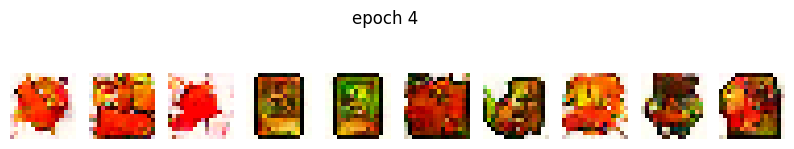

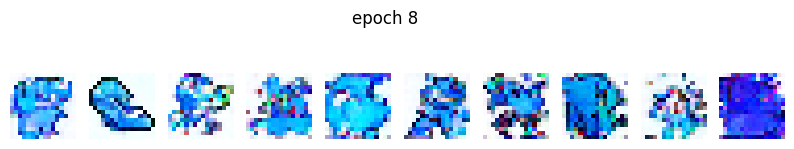

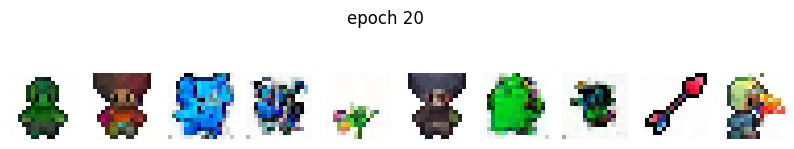

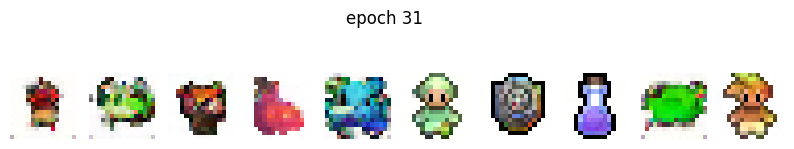

In [ ]:
# on the drive there is no model_5 and model_10 (only 0, 4, 8, ...), so we take 4 and 8
for ep in [4, 8, 20, 31]:
    nn_model.load_state_dict(torch.load(f"./models/model_{ep}.pth", map_location=device))
    nn_model.eval()
    samples, _ = sample_ddpm(10)

    plt.figure(figsize=(10, 2))
    for i in range(10):
        plt.subplot(1, 10, i + 1)
        plt.imshow((samples[i].permute(1, 2, 0).cpu().numpy().clip(-1, 1) + 1) / 2)
        plt.axis("off")
    plt.suptitle(f"epoch {ep}")
    plt.show()

**Observation:** after few epochs (4, 8) the samples are mostly colored blobs with noise, we can guess a shape but not the details. At epoch 20 the sprites appear (body, head, outline) and at epoch 31 they are clean with more details and different characters/objects. So the more the model is trained, the better it predicts the noise, and the better the generated images.

## 6. Building DDIM Denoising and Sampling Functions

In DDIM (Denoising Diffusion Implicit Model), we use a deterministic approach to remove noise step-by-step, rather than relying on stochastic diffusion like in DDPM. Below is an explanation of how we implement `denoise_ddim()` and `sample_ddim()`.

This function removes noise from a given image $x_t$ at timestep $t$, using the model’s predicted noise $\epsilon_\theta(x_t,t)$.

**We estimate the clean image $x_0$:**

$$\hat x_0=\frac{x_t-\sqrt{1-\bar\alpha_t}\,\epsilon_\theta(x_t,t)}{\sqrt{\bar\alpha_t}}$$

**Then, we compute the direction pointing to $x_t$:**

$$\text{dir}_{x_t}=\sqrt{1-\bar\alpha_{t-1}}\,\epsilon_\theta(x_t,t)$$

**Finally, we reconstruct $x_{t-1}$ as:**

$$x_{t-1}=\sqrt{\bar\alpha_{t-1}}\,\hat x_0+\text{dir}_{x_t}$$

In [ ]:
# define sampling function for DDIM
# removes the noise using ddim
def denoise_ddim(x, t, t_prev, pred_noise):
   ab = ab_t[t]
   ab_prev = ab_t[t_prev]

   x0_pred = ab_prev.sqrt() / ab.sqrt() * (x - (1 - ab).sqrt() * pred_noise)
   dir_xt = (1 - ab_prev).sqrt() * pred_noise

   return x0_pred + dir_xt

The next function generates images by iteratively applying the denoising function from pure noise $x_T$ to a final image $x_0$.

- We initialize random Gaussian noise $x_T \sim \mathcal{N}(0,I)$.
- **Iterative reverse diffusion:**
  - Denoise step-by-step from $x_T$ to $x_0$.
  - Instead of 1000+ steps (like DDPM), DDIM reduces this to ~20–50 steps.

In [ ]:
# sample quickly using DDIM
@torch.no_grad()
def sample_ddim(n_sample, n=20):
   # x_T ~ N(0, 1), sample initial noise
   samples = torch.randn(n_sample, 3, height, height).to(device)

   # array to keep track of generated steps for plotting
   intermediate = []
   step_size = timesteps // n
   for i in range(timesteps, 0, -step_size):
       print(f'sampling timestep {i:3d}', end='\r')

       # reshape time tensor
       t = torch.tensor([i / timesteps])[:, None, None, None].to(device)

       eps = nn_model(samples, t)    # predict noise e_(x_t,t)
       samples = denoise_ddim(samples, i, i - step_size, eps)
       intermediate.append(samples.detach().cpu().numpy())

   intermediate = np.stack(intermediate)
   return samples, intermediate

# visualize samples
plt.clf()
samples, intermediate = sample_ddim(32, n=25)
animation_ddim = plot_sample(intermediate,32,4,save_dir, "ani_run", None, save=False)
HTML(animation_ddim.to_jshtml())

<Figure size 640x480 with 0 Axes>